# Quantum Billiards and Scars

## Goal
The goal of this project is to study how the shape of a billiard affects its quantum eigenstates.

I will first solve the Schrödinger equation for a rectangular billiard and compare the numerical eigenvalues with the analytical results.

Then, I will study a stadium-shaped billiard and look for possible quantum scars.

## Step 1: Setting up the rectangular billiard

First, we create a 2D grid representing a rectangular billiard.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import diags
from scipy.sparse.linalg import eigsh

## Step 2: Creating the grid

I define the dimensions of the rectangle and create a 2D grid.

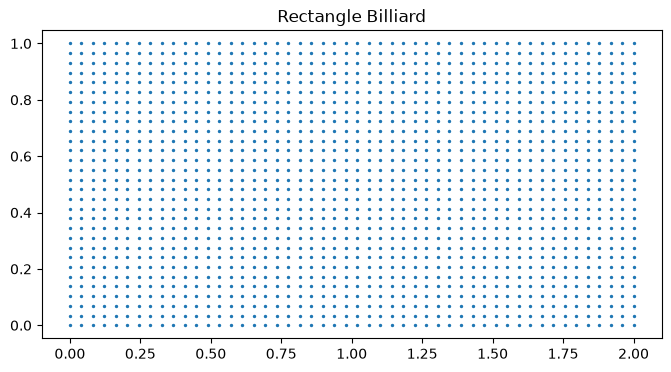

In [2]:
Lx = 2.0
Ly = 1.0

Nx = 50
Ny = 30

x = np.linspace(0, Lx, Nx)
y = np.linspace(0, Ly, Ny)

X, Y = np.meshgrid(x, y)

plt.figure(figsize=(8, 4))
plt.scatter(X, Y, s=2)
plt.axis("equal")
plt.title("Rectangle Billiard")
plt.show()

## Step 3: Solving the Schrödinger Equation

I use the finite difference method to solve the 2D Schrödinger equation.

The wavefunction is zero at the boundaries.

My goal is to calculate the first 10 eigenvalues and eigenstates.

In [3]:
from scipy.sparse import diags, kron, eye
from scipy.sparse.linalg import eigsh

dx = Lx / (Nx - 1)
dy = Ly / (Ny - 1)

nx = Nx - 2
ny = Ny - 2

Dx = diags([-np.ones(nx-1), 2*np.ones(nx), -np.ones(nx-1)], [-1, 0, 1]) / dx**2

Dy = diags([-np.ones(ny-1), 2*np.ones(ny), -np.ones(ny-1)], [-1, 0, 1]) / dy**2

H = kron(eye(ny), Dx) + kron(Dy, eye(nx))

energies, states = eigsh(H, k=10, which='SM')

order = np.argsort(energies)
energies = energies[order]
states = states[:, order]

print("First 10 numerical eigenvalues:")

for i, E in enumerate(energies):
    print(f"State {i+1}: E = {E:.4f}")

First 10 numerical eigenvalues:
State 1: E = 12.3265
State 2: E = 19.7160
State 3: E = 31.9982
State 4: E = 41.7908
State 5: E = 49.1225
State 6: E = 49.1803
State 7: E = 61.4625
State 8: E = 71.0185
State 9: E = 78.5867
State 10: E = 90.5139


## Step 4: Comparing Numerical and Analytical Eigenvalues

I compare the numerical results with the analytical values to check the accuracy of our finite difference method.

In [ ]:
analytical = []

for n in range(1, 10):
    for m in range(1, 10):
        E = np.pi**2 * (n**2 / Lx**2 + m**2 / Ly**2)
        analytical append(E)

analytical = np.sort(analytical)[:10]

print("State | Numerical | Analytical | Error (%)")

for i in range(10):
    error = abs(energies[i] - analytical[i]) / analytical[i] * 100
    print(f"{i+1:5d} | {energies[i]:9.4f} | {analytical[i]:10.4f} | {error:.3f}%")


## Step 5: Creating a Stadium Billiard

Now we change the geometry from a rectangle to a stadium.

The stadium consists of a rectangle with two semicircular ends.

We use a mask to define which grid points are inside the stadium.

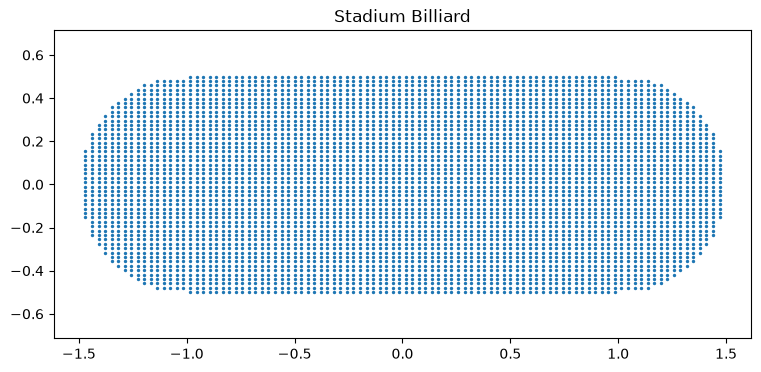

In [4]:

L = 2.0
R = 0.5

x = np.linspace(-L/2 - R, L/2 + R, 100)
y = np.linspace(-R, R, 50)

X, Y = np.meshgrid(x, y)

rectangle = (np.abs(X) <= L/2) & (np.abs(Y) <= R)

left = (X + L/2)**2 + Y**2 <= R**2

right = (X - L/2)**2 + Y**2 <= R**2

stadium = rectangle | left | right

plt.figure(figsize=(9, 4))
plt.scatter(X[stadium], Y[stadium], s=2)
plt.axis("equal")
plt.title("Stadium Billiard")
plt.show()

## Step 6: Solving the Schrödinger Equation for the Stadium

We use the finite difference method to calculate the eigenvalues and eigenstates of the stadium billiard.

The stadium mask defines the region where the particle can exist.

In [5]:
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import eigsh

dx = x[1] - x[0]
dy = y[1] - y[0]

points = np.argwhere(stadium)
N = len(points)

index = -np.ones(stadium.shape, dtype=int)

for k, (i, j) in enumerate(points):
    index[i, j] = k

H = lil_matrix((N, N))

for k, (i, j) in enumerate(points):
    H[k, k] = 2/dx**2 + 2/dy**2

    for di, dj, weight in [
        (0, 1, -1/dx**2),
        (0, -1, -1/dx**2),
        (1, 0, -1/dy**2),
        (-1, 0, -1/dy**2)
    ]:
        ni = i + di
        nj = j + dj

        if 0 <= ni < stadium.shape[0] and 0 <= nj < stadium.shape[1]:
            if stadium[ni, nj]:
                H[k, index[ni, nj]] = weight

H = H.tocsr()

stadium_energies, stadium_states = eigsh(H, k=10, which="SM")

order = np.argsort(stadium_energies)

stadium_energies = stadium_energies[order]
stadium_states = stadium_states[:, order]

print("First 10 stadium eigenvalues:")

for i, E in enumerate(stadium_energies):
    print(f"State {i+1}: E = {E:.4f}")

First 10 stadium eigenvalues:
State 1: E = 10.3379
State 2: E = 13.9967
State 3: E = 19.9997
State 4: E = 28.2395
State 5: E = 37.8108
State 6: E = 38.6211
State 7: E = 42.0039
State 8: E = 48.8356
State 9: E = 51.0823
State 10: E = 58.1026


## Step 7: Visualizing Stadium Eigenstates

We plot the probability density of the first 10 eigenstates of the stadium billiard.

The probability density is given by |ψ|² and shows where the particle is more likely to be found.

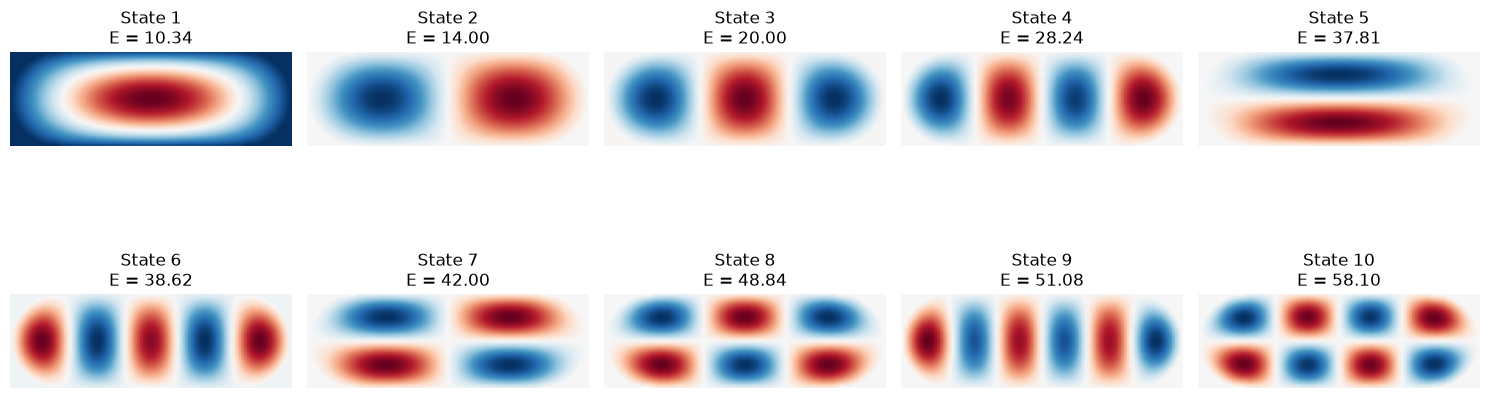

In [8]:

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i in range(10):

    psi = np.zeros(stadium.shape)

    psi[points[:, 0], points[:, 1]] = stadium_states[:, i]

    ax = axes.flat[i]

    ax.imshow(
    psi,
    extent=[x.min(), x.max(), y.min(), y.max()],
    origin="lower",
    cmap="RdBu"
)

    ax.set_title(f"State {i+1}\nE = {stadium_energies[i]:.2f}")
    ax.set_aspect("equal")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:

num_states = 100

stadium_energies, stadium_states = eigsh(H, k=num_states, which="SM")

order = np.argsort(stadium_energies)

stadium_energies = stadium_energies[order]
stadium_states = stadium_states[:, order]

print("Number of eigenstates:", len(stadium_energies))

Number of eigenstates: 100


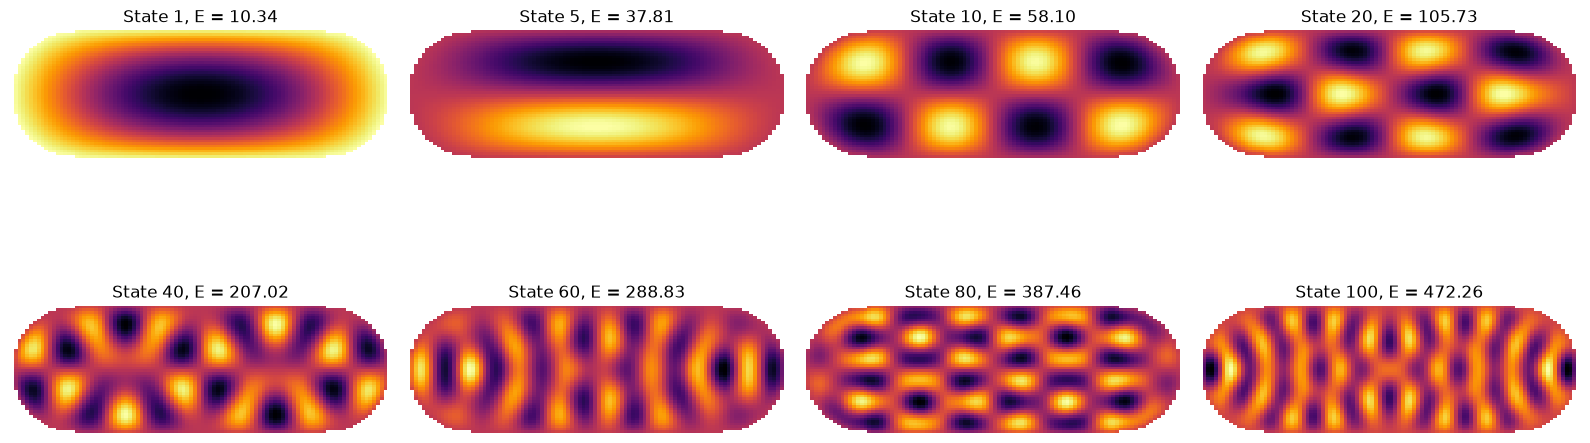

In [10]:

selected_states = [0, 4, 9, 19, 39, 59, 79, 99]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for i, state in enumerate(selected_states):

    psi = np.zeros(stadium.shape)

    psi[points[:, 0], points[:, 1]] = stadium_states[:, state]

    psi = np.ma.masked_where(~stadium, psi)

    ax = axes.flat[i]

    ax.imshow(
        psi,
        extent=[x.min(), x.max(), y.min(), y.max()],
        origin="lower",
        cmap="inferno",
        interpolation="nearest"
    )

    ax.set_title(
        f"State {state+1}, E = {stadium_energies[state]:.2f}"
    )

    ax.set_aspect("equal")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Step 8: Calculating the Inverse Participation Ratio (IPR)

We calculate more eigenstates of the stadium billiard.

The inverse participation ratio (IPR) measures how localized each wavefunction is.

We use IPR to identify highly localized states that may be candidates for quantum scars.

In [11]:

ipr_values = []

for i in range(num_states):

    psi = stadium_states[:, i]

    psi = psi / np.sqrt(np.sum(np.abs(psi)**2) * dx * dy)

    ipr = np.sum(np.abs(psi)**4) * dx * dy

    ipr_values.append(ipr)

ipr_values = np.array(ipr_values)

print("First 10 IPR values:")

for i in range(10):
    print(f"State {i+1}: IPR = {ipr_values[i]:.4f}")

First 10 IPR values:
State 1: IPR = 0.7608
State 2: IPR = 0.7578
State 3: IPR = 0.7616
State 4: IPR = 0.7709
State 5: IPR = 0.8140
State 6: IPR = 0.7822
State 7: IPR = 0.8015
State 8: IPR = 0.7898
State 9: IPR = 0.7931
State 10: IPR = 0.7839


## Step 9: IPR vs Energy

We plot the inverse participation ratio as a function of energy to identify highly localized eigenstates.

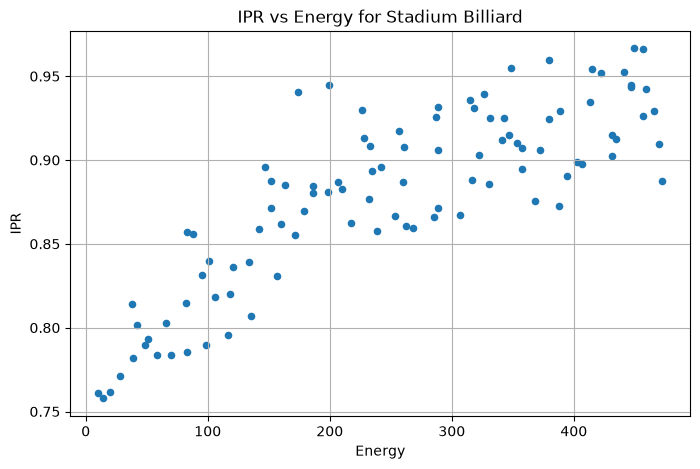

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(stadium_energies, ipr_values, s=20)

plt.xlabel("Energy")
plt.ylabel("IPR")
plt.title("IPR vs Energy for Stadium Billiard")

plt.grid(True)
plt.show()

## Step 10: Most Localized Eigenstates

We select the 20 eigenstates with the highest IPR values and visualize their probability densities.

These states may contain interesting localization patterns.

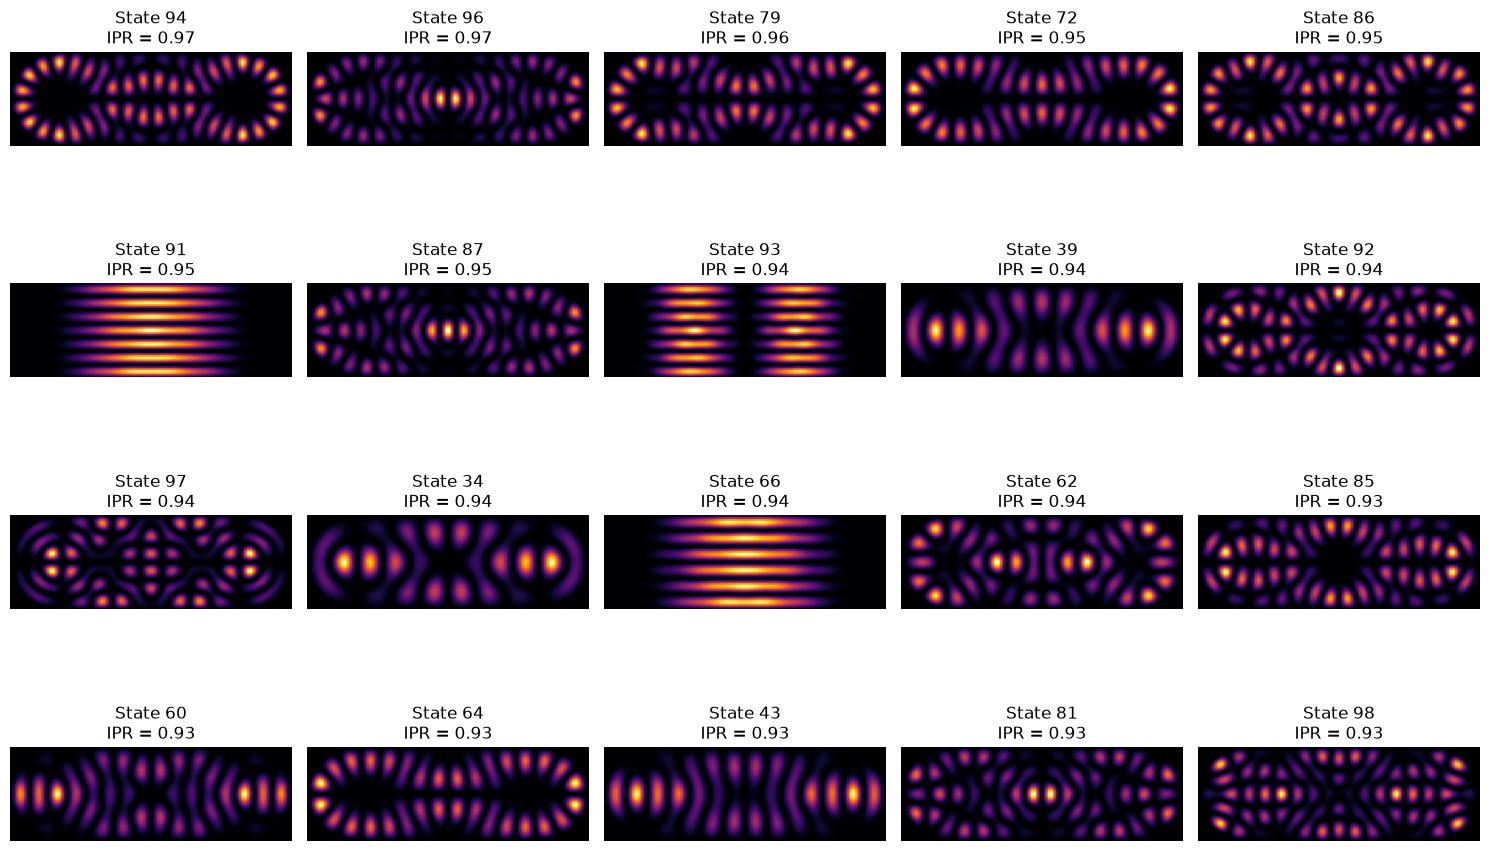

In [13]:

top_states = np.argsort(ipr_values)[-20:][::-1]

fig, axes = plt.subplots(4, 5, figsize=(15, 10))

for i, state in enumerate(top_states):

    psi = np.zeros(stadium.shape)

    psi[points[:, 0], points[:, 1]] = stadium_states[:, state]

    probability = psi**2

    ax = axes.flat[i]

    ax.imshow(
        probability,
        extent=[x.min(), x.max(), y.min(), y.max()],
        origin="lower",
        cmap="inferno"
    )

    ax.set_title(f"State {state+1}\nIPR = {ipr_values[state]:.2f}")
    ax.set_aspect("equal")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Step 11: Examining Possible Quantum Scars

We examine selected eigenstates that show interesting spatial patterns.

In particular, we look for wavefunction structures that may be associated with classical periodic orbits.

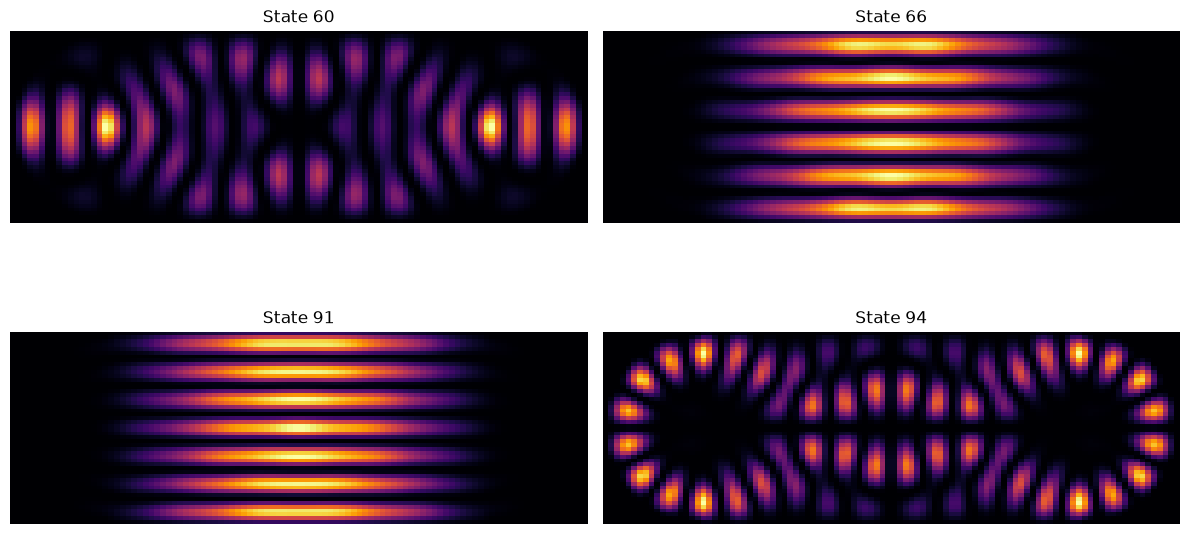

In [14]:

selected_states = [60, 66, 91, 94]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for i, state in enumerate(selected_states):

    psi = np.zeros(stadium.shape)

    psi[points[:, 0], points[:, 1]] = stadium_states[:, state - 1]

    probability = psi**2

    ax = axes.flat[i]

    ax.imshow(
        probability,
        extent=[x.min(), x.max(), y.min(), y.max()],
        origin="lower",
        cmap="inferno"
    )

    ax.set_title(f"State {state}")
    ax.set_aspect("equal")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Step 12: Energy Level Spacing Statistics

We study the spacing between neighboring energy levels of the stadium billiard.

Level spacing statistics can help us understand the difference between regular and chaotic quantum systems.

In [15]:

spacings = np.diff(stadium_energies)

print("First 10 energy spacings:")

for i in range(10):
    print(f"Spacing {i+1}: {spacings[i]:.4f}")

First 10 energy spacings:
Spacing 1: 3.6587
Spacing 2: 6.0030
Spacing 3: 8.2398
Spacing 4: 9.5713
Spacing 5: 0.8103
Spacing 6: 3.3828
Spacing 7: 6.8317
Spacing 8: 2.2467
Spacing 9: 7.0202
Spacing 10: 7.4736


## Step 13: Plotting Energy Level Spacings

We plot a histogram of the energy spacings to examine their distribution.

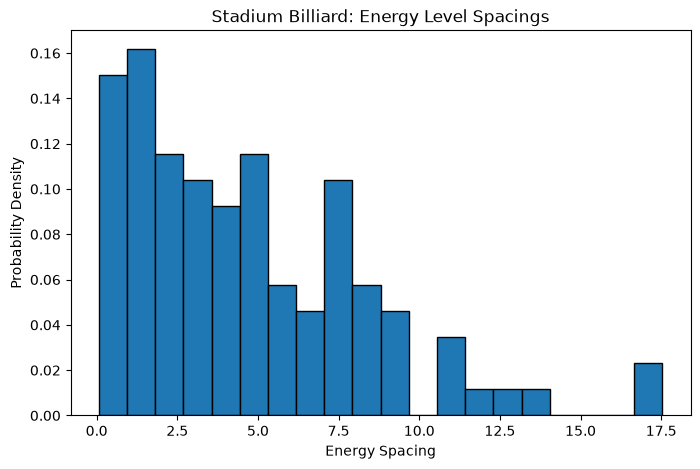

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(
    spacings,
    bins=20,
    density=True,
    edgecolor="black"
)

plt.xlabel("Energy Spacing")
plt.ylabel("Probability Density")
plt.title("Stadium Billiard: Energy Level Spacings")

plt.show()

## Step 14: Normalized Energy Spacings

We divide the energy spacings by their mean value.

This provides a preliminary normalized spacing distribution.

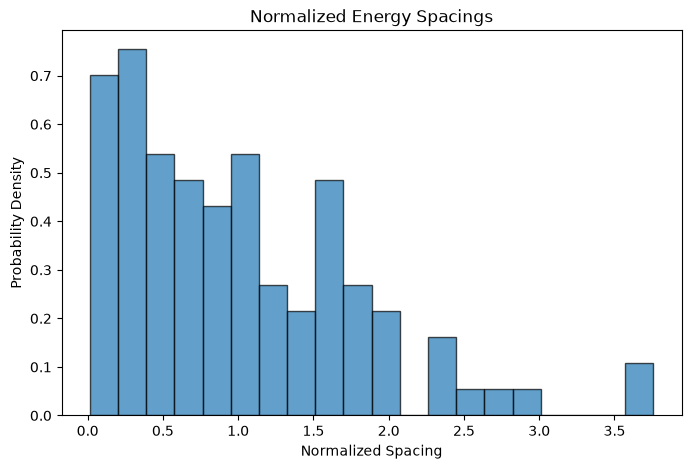

In [17]:


normalized_spacings = spacings / np.mean(spacings)

plt.figure(figsize=(8, 5))

plt.hist(
    normalized_spacings,
    bins=20,
    density=True,
    alpha=0.7,
    edgecolor="black"
)

plt.xlabel("Normalized Spacing")
plt.ylabel("Probability Density")
plt.title("Normalized Energy Spacings")

plt.show()

## Step 15: Comparison with Theoretical Distributions

We compare the normalized energy spacings with the Poisson and Wigner distributions.

The comparison is preliminary because the spectrum has not been fully unfolded or separated into symmetry sectors.

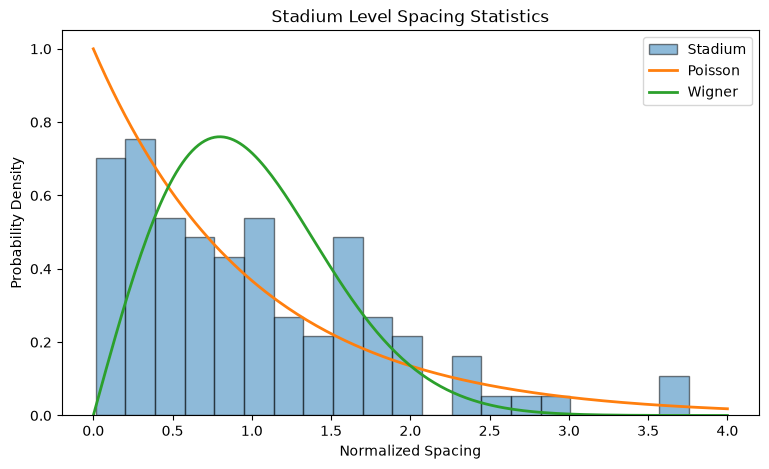

In [ ]:
s = np.linspace(0, 4, 200)

poisson = np.exp(-s)

wigner = (np.pi / 2) * s * np.exp(-np.pi * s**2 / 4)

plt.figure(figsize=(9, 5))

plt.hist(
    normalized_spacings,
    bins=20,
    density=True,
    alpha=0.5,
    label="Stadium",
    edgecolor="black"
)

plt.plot(s, poisson, label="Poisson", linewidth=2)
plt.plot(s, wigner, label="Wigner", linewidth=2)

plt.xlabel("Normalized Spacing")
plt.ylabel("Probability Density")
plt.title("Stadium Level Spacing Statistics")

plt.legend()
plt.show()